## Understanding data

In [33]:
import pandas as pd 

In [34]:
df = pd.read_csv("../data/processed/weather_daily.csv") 

In [12]:
df.shape

(3927, 6)

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3927 entries, 0 to 3926
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 3927 non-null   str    
 1   temperature_2m_max   3927 non-null   float64
 2   temperature_2m_min   3927 non-null   float64
 3   temperature_2m_mean  3927 non-null   float64
 4   precipitation_sum    3927 non-null   float64
 5   wind_speed_10m_max   3927 non-null   float64
dtypes: float64(5), str(1)
memory usage: 184.2 KB


In [5]:
df.head()

,date,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,wind_speed_10m_max
0,2016-01-01,18.9,5.9,11.1,0.0,5.9
1,2016-01-02,18.4,4.2,10.4,0.0,8.0
2,2016-01-03,19.8,4.8,11.5,0.0,7.6
3,2016-01-04,17.0,9.4,12.7,3.7,10.9
4,2016-01-05,18.3,7.4,12.2,0.0,10.2


In [6]:
df.sample(5)

,date,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,wind_speed_10m_max
1168,2019-03-14,17.1,9.4,12.5,1.1,13.3
2147,2021-11-17,22.4,10.1,15.5,0.0,8.0
96,2016-04-06,24.8,14.4,19.2,2.6,11.2
1821,2020-12-26,17.1,6.0,10.6,0.0,9.9
1095,2018-12-31,18.7,3.8,10.0,0.0,10.2


In [7]:
df.describe()

,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,wind_speed_10m_max
count,3927.000000,3927.000000,3927.000000,3927.000000,3927.000000
mean,27.113598,16.576089,21.477209,2.760148,12.954596
std,7.257967,7.128190,7.283903,7.736748,4.513832
min,9.200000,1.000000,6.700000,0.000000,3.600000
25%,20.800000,10.000000,14.800000,0.000000,9.700000
50%,28.800000,17.500000,23.100000,0.000000,12.000000
75%,32.600000,23.200000,27.700000,1.600000,15.300000
max,44.200000,30.600000,36.900000,161.300000,40.800000


In [8]:
df.isnull().sum()

date                   0
temperature_2m_max     0
temperature_2m_min     0
temperature_2m_mean    0
precipitation_sum      0
wind_speed_10m_max     0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

## Univariate Analysis

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3927 entries, 0 to 3926
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 3927 non-null   str    
 1   temperature_2m_max   3927 non-null   float64
 2   temperature_2m_min   3927 non-null   float64
 3   temperature_2m_mean  3927 non-null   float64
 4   precipitation_sum    3927 non-null   float64
 5   wind_speed_10m_max   3927 non-null   float64
dtypes: float64(5), str(1)
memory usage: 184.2 KB


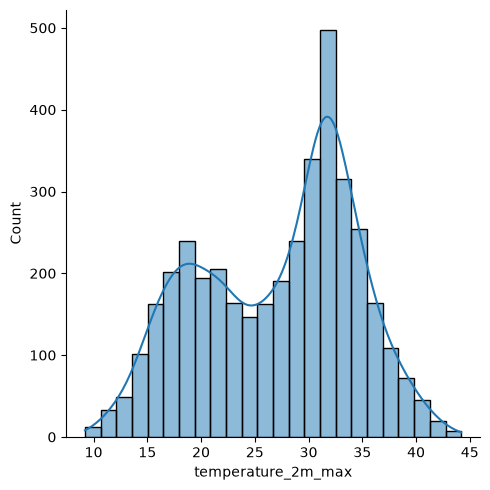

In [14]:
sns.displot(df['temperature_2m_max'], kde=True)

The distribution of maximum daily temperatures is centered around a moderate range, with most values clustered in the 15�25�C band. This suggests a generally warm climate with occasional hotter days.

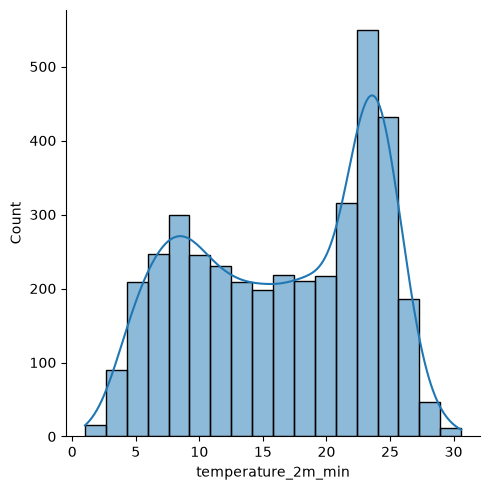

In [15]:
sns.displot(df['temperature_2m_min'], kde=True)

Minimum temperatures are concentrated at cooler values, mostly between 5�C and 12�C. The curve indicates frequent cool nights and a smaller number of colder extremes.

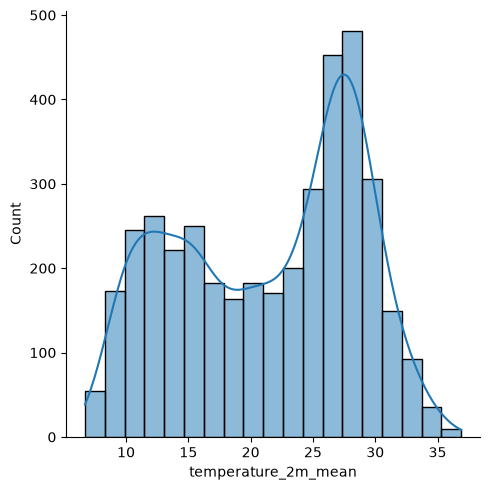

In [20]:
sns.displot(df['temperature_2m_mean'], kde=True)

The daily mean temperature distribution is fairly centered around the mid-teens, reflecting a stable seasonal pattern with moderate variation across the year.

C:\Users\abdur\AppData\Local\Temp\ipykernel_14248\571690477.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['precipitation_sum'],kde=True)


<Axes: xlabel='precipitation_sum', ylabel='Density'>

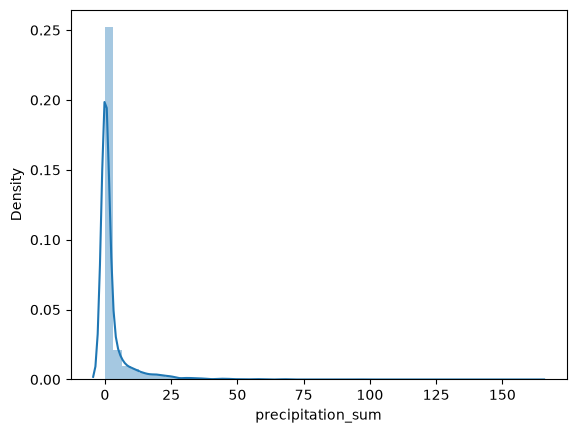

In [18]:
sns.distplot(df['precipitation_sum'],kde=True)

Most days receive very little rainfall, while a long right tail shows a few days with much heavier precipitation. This pattern suggests a dry dataset with occasional wetter periods.

<Axes: xlabel='precipitation_sum'>

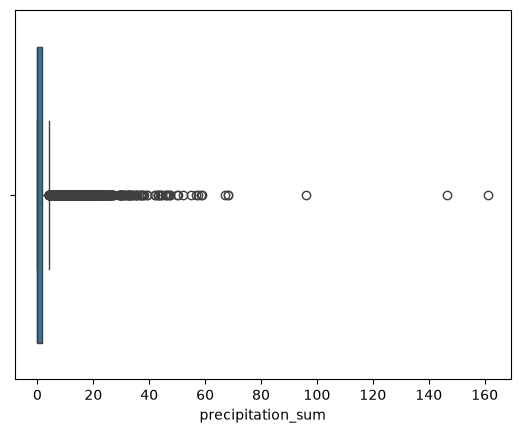

In [19]:
sns.boxplot(x=df['precipitation_sum'])

The boxplot confirms that precipitation is strongly right-skewed, with the median close to zero and a handful of days showing much higher rainfall totals.

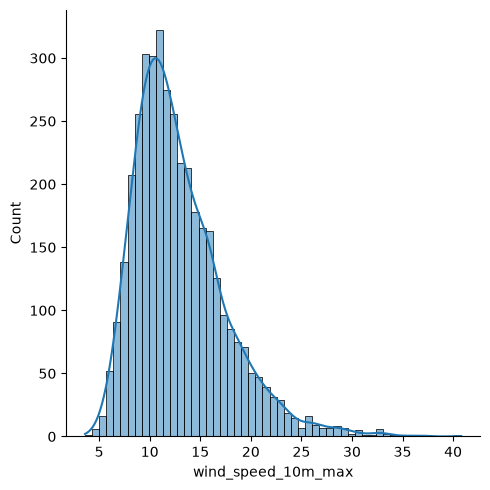

In [21]:
sns.displot(df['wind_speed_10m_max'], kde=True)

Wind speeds are mostly moderate, with a concentrated distribution and a few stronger gust days. This suggests generally calm conditions with occasional windier episodes.

## Bivariate Analysis

In [38]:
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day-of-year'] = df['date'].dt.dayofyear

df = df.sort_values('date').reset_index(drop=True)

C:\Users\abdur\AppData\Local\Temp\ipykernel_14940\104381057.py:4: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df['day-of-year'] = df['date'].dt.dayofyear


<Axes: xlabel='temperature_2m_max', ylabel='temperature_2m_min'>

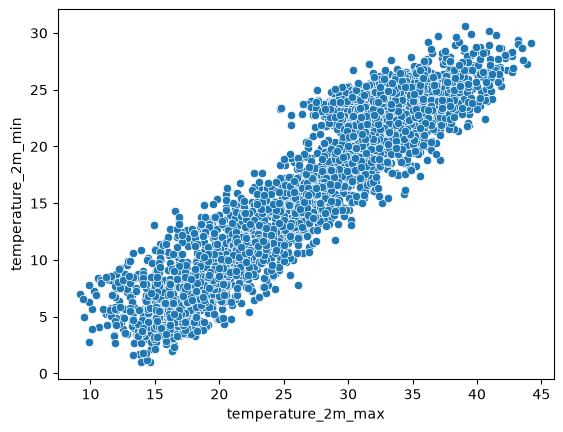

In [23]:
sns.scatterplot(x=df['temperature_2m_max'], y=df['temperature_2m_min'])

Higher maximum temperatures usually coincide with higher minimum temperatures, indicating warmer days and nights tend to occur together.

<Axes: xlabel='day-of-year', ylabel='temperature_2m_max'>

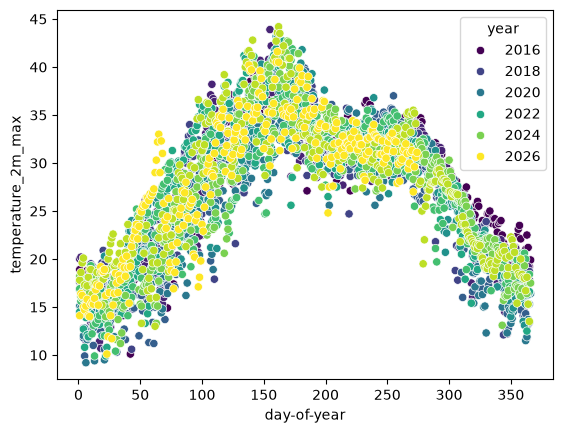

In [28]:
sns.scatterplot(x=df['day-of-year'], y=df['temperature_2m_max'], hue=df['year'], palette='viridis')

Temperature rises steadily through the year and falls again after mid-year, showing a clear seasonal cycle across years.

<Axes: xlabel='month', ylabel='temperature_2m_max'>

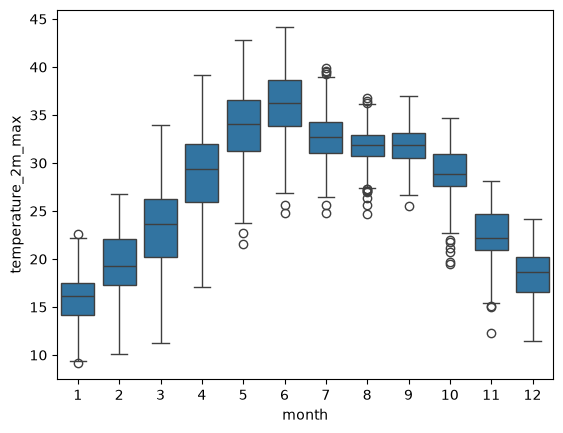

In [34]:
sns.boxplot(y=df["temperature_2m_max"], x=df["month"])

Monthly maximum temperatures are lowest in winter and highest in summer, confirming a strong seasonal pattern.

In [36]:
df['tomorrow_max'] = df['temperature_2m_max'].shift(-1)

In [40]:
df.corr(numeric_only=True)['tomorrow_max'].sort_values(ascending=False)

tomorrow_max           1.000000
temperature_2m_max     0.961769
temperature_2m_mean    0.954471
temperature_2m_min     0.908851
month                  0.168167
day-of-year            0.165557
wind_speed_10m_max     0.104092
year                   0.033042
precipitation_sum     -0.054006
Name: tomorrow_max, dtype: float64

#### temperature_2m_mean ($r \approx 0.954$): Almost equally strong ($0.95$).
#### temperature_2m_min ($r \approx 0.909$): Still strongly correlated above $0.90$.
#### wind_speed_10m_max ($r \approx 0.104$): Very weak linear correlation.
#### precipitation_sum ($r \approx -0.054$): Near zero (slightly negative, meaning heavy rain days tend to slightly cool things off, but it's not a strong linear line on its own).

<Axes: >

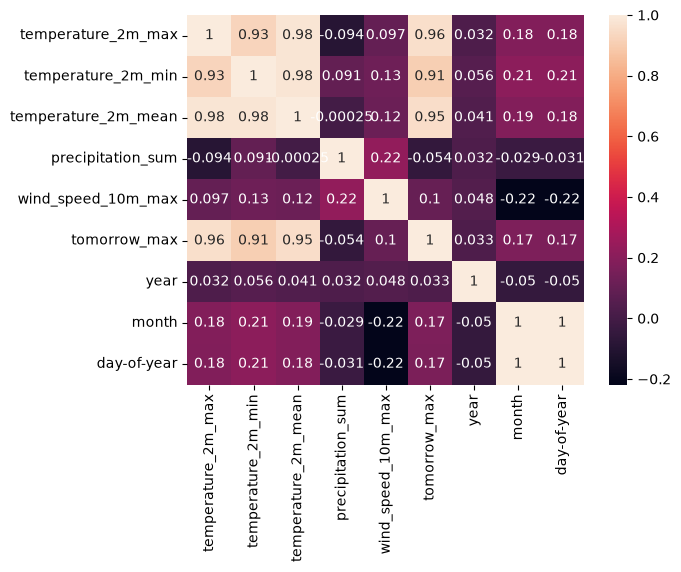

In [43]:
sns.heatmap(df.corr(numeric_only=True), annot=True)